# LoRa: чирпы, которые слышно на 20 дБ ниже шума

**CSS (chirp spread spectrum).** Базовый символ — чирп: частота линейно пробегает всю полосу $B$ за время $T_s=2^{SF}/B$. Символ $s\in\{0,\dots,N-1\}$, $N=2^{SF}$ — тот же чирп, **циклически сдвинутый** по частоте на $s\,B/N$: начинается с $f_0=-B/2+sB/N$, доходит до $+B/2$ и заворачивается вниз. Один символ несёт $SF$ бит.

При дискретизации с частотой $f_s=B$ символ — это $N$ отсчётов:
$$x_s[n]=\exp\Big\{j2\pi\Big(\frac{n^2}{2N}+\big(\tfrac sN-\tfrac12\big)n\Big)\Big\},\qquad n=0,\dots,N-1$$
(заворот частоты при $f_s=B$ получается сам — частоты $f$ и $f-B$ неразличимы).

**Демодуляция** — умножить на сопряжённый базовый чирп (dechirp) и сделать FFT:
$$x_s[n]\cdot x_0^*[n]=e^{\,j2\pi sn/N}\;\xrightarrow{\text{FFT}}\;N\,\delta[k-s]$$
Квадратичная фаза уничтожается, остаётся тон на бине $s$. Шум белый и после умножения на чирп с $|x_0|=1$ остаётся белым: в каждом из $N$ бинов его мощность $N\sigma^2$, а пик сигнала — $N^2$. **Выигрыш обработки** $N=2^{SF}$: от 21 дБ (SF7) до 36 дБ (SF12) — тот же механизм, что в DSSS из ноутбука про CDMA, только «кодом» служит чирп, и вместо одного бита на $N$ чипов здесь $SF$ бит.

По сути это **$M$-ичная ортогональная** модуляция ($M=N$) с некогерентным приёмом: решение — максимум из $N$ бинов. Отсюда и теория SER, и главное свойство: с ростом $M$ нужное $E_b/N_0$ **падает** к пределу Шеннона $-1.59$ дБ, а платим скоростью — $R_b=SF\cdot B/2^{SF}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import ncx2

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
SF = 9              # 7…12
BW = 125e3          # 125 / 250 / 500 кГц
SNR_DB = -12        # SNR в полосе B для разделов 2, 4, 5
FC_MHZ = 868
PPM = 10            # нестабильность кварцев (передатчик + приёмник)
TIMING = 37         # смещение окна приёмника, отсчётов (раздел 4)
JSR_DB = 10         # тон-помеха относительно сигнала (раздел 5)

rng = np.random.default_rng(SEED)

## Примитивы: модулятор, демодулятор, канал, теория SER

In [2]:
def chirp(sym, sf, os=1, down=False):
    """Символы sym (...,) → чирпы (..., N·os) при f_s = os·B.
    os = 1: формула x_s[n] (периодична по N, x_s — циклический сдвиг x_0); os > 1 (для картинок):
    фаза — интеграл мгновенной частоты с явным заворотом от +B/2 к −B/2."""
    N = 2**sf
    sym = np.asarray(sym)
    if os == 1:
        n = np.arange(N)
        x = np.exp(2j * np.pi * (n**2 / (2 * N) + (sym[..., None] / N - 0.5) * n))
    else:
        t = np.arange(N * os) / os
        f = ((sym[..., None] + t) % N) / N - 0.5                 # мгновенная частота в единицах B
        x = np.exp(2j * np.pi * np.concatenate([np.zeros(sym.shape + (1,)), np.cumsum(f, -1)[..., :-1]], -1) / os)
    return np.conj(x) if down else x

def demod(r, sf, return_spec=False):
    """r (..., N) → решение argmax|FFT(r · down-chirp)|"""
    Y = np.fft.fft(r * chirp(0, sf, down=True), axis=-1)
    s = np.abs(Y).argmax(-1)
    return (s, Y) if return_spec else s

def awgn(shape, snr_db, rng):
    """Комплексный шум с мощностью 1/SNR на отсчёт (сигнал единичной мощности, шум в полосе f_s = B)."""
    s = np.sqrt(10 ** (-snr_db / 10) / 2)
    return s * (rng.standard_normal(shape) + 1j * rng.standard_normal(shape))

def ser_theory(sf, snr_db):
    """Некогерентный приём M-ичных ортогональных сигналов: правильный бин — райсовский, остальные N−1 — релеевские.
    x = |Y|²/(Nσ²): шумовой бин ~ Exp(1), сигнальный ~ ½·χ'²(2, 2λ), λ = N·SNR."""
    N = 2**sf
    out = []
    for snr in np.atleast_1d(snr_db):
        lam = N * 10 ** (snr / 10)
        pc = lambda x: 2 * ncx2.pdf(2 * x, 2, 2 * lam) * np.exp((N - 1) * np.log1p(-np.exp(-x)))
        a, b = max(1e-9, lam - 12 * np.sqrt(lam + 1) - 5), lam + 12 * np.sqrt(lam + 1) + 30
        out.append(max(0.0, 1 - quad(pc, a, b, limit=400, points=[lam])[0]))
    return np.array(out)

def sim_ser(sf, snr_db, n_sym, rng, batch=500, cfo_bins=0.0):
    errs = 0; done = 0; N = 2**sf
    rot = np.exp(2j * np.pi * cfo_bins * np.arange(N) / N)
    while done < n_sym:
        b = min(batch, n_sym - done)
        s = rng.integers(0, N, b)
        r = chirp(s, sf) * rot + awgn((b, N), snr_db, rng)
        errs += np.sum(demod(r, sf) != s); done += b
    return errs / n_sym

def bitrate(sf, bw=BW, cr=1):
    return sf * bw / 2**sf * 4 / (4 + cr)

def time_on_air(pl, sf, bw=BW, cr=1, n_pre=8, crc=True, implicit=False):
    """Semtech AN1200.13: длительность пакета, с. DE (low data rate optimize) включается при T_sym > 16 мс."""
    ts = 2**sf / bw
    de = 1 if ts > 16e-3 else 0
    npl = 8 + max(int(np.ceil((8 * pl - 4 * sf + 28 + 16 * crc - 20 * implicit) / (4 * (sf - 2 * de)))) * (cr + 4), 0)
    return (n_pre + 4.25) * ts + npl * ts

N = 2**SF
_s = np.arange(N)
assert np.all(demod(chirp(_s, SF), SF) == _s)
print(f"SF{SF}, B = {BW/1e3:.0f} кГц: N = {N} отсчётов на символ, T_s = {N/BW*1e3:.2f} мс, "
      f"бин FFT = {BW/N:.0f} Гц, R_b = {bitrate(SF):.0f} бит/с (CR 4/5)")
print(f"Выигрыш обработки 10·log10(N) = {10*np.log10(N):.1f} дБ")
print(f"Огибающая: max|x|/min|x| = {np.abs(chirp(_s, SF)).max() / np.abs(chirp(_s, SF)).min():.3f} — PAPR 0 дБ")

SF9, B = 125 кГц: N = 512 отсчётов на символ, T_s = 4.10 мс, бин FFT = 244 Гц, R_b = 1758 бит/с (CR 4/5)
Выигрыш обработки 10·log10(N) = 27.1 дБ
Огибающая: max|x|/min|x| = 1.000 — PAPR 0 дБ


## 1. Как выглядит пакет
Спектрограмма пакета LoRa (×8 передискретизация, чтобы был виден заворот частоты): 8 базовых up-чирпов преамбулы, 2 символа sync word (номер сети), 2.25 down-чирпа, затем данные — up-чирпы со случайными начальными частотами. Справа — мгновенная частота трёх символов данных: «пила» с разрывом там, где частота дошла до $+B/2$. Положение разрыва и кодирует символ.

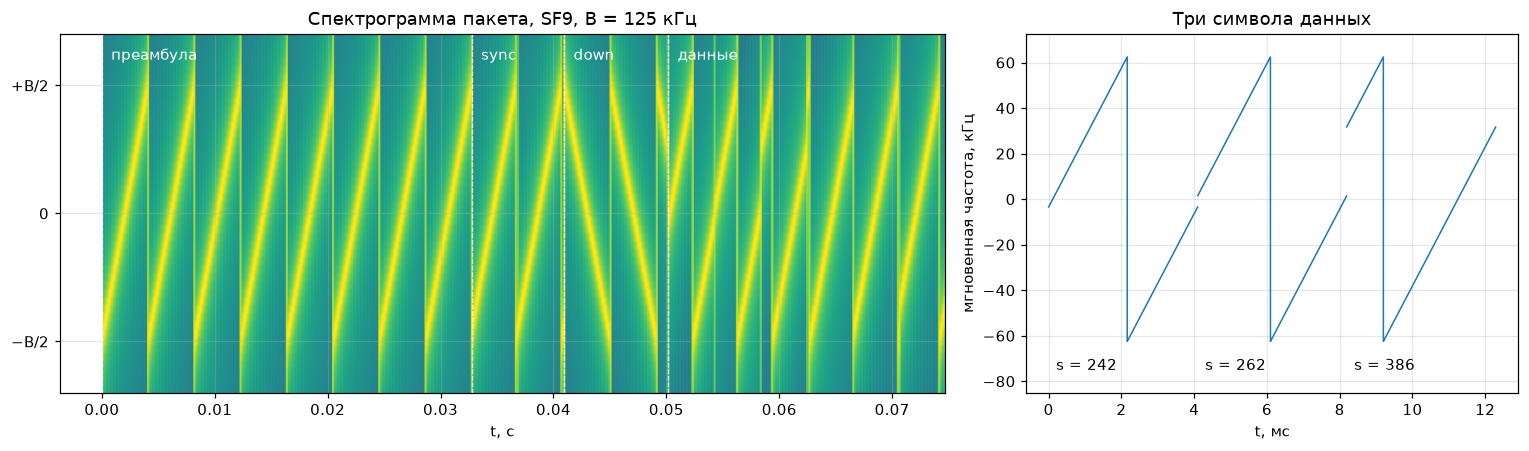

Пакет: 9344.0 отсчётов = 74.8 мс


In [3]:
OS = 8
data = rng.integers(0, N, 6)
parts = [chirp(np.zeros(8, int), SF, OS), chirp(np.array([24, 32]), SF, OS),
         chirp(np.zeros(3, int), SF, OS, down=True).ravel()[:int(2.25 * N * OS)], chirp(data, SF, OS)]
pkt = np.concatenate([p.ravel() for p in parts])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.8, 1]})
nfft = max(64, N * OS // 16)
ax[0].specgram(pkt, NFFT=nfft, Fs=OS * BW, noverlap=nfft * 3 // 4, cmap="viridis", sides="twosided")
ax[0].set_ylim(-0.7 * BW, 0.7 * BW)
ax[0].set_yticks(np.array([-0.5, 0, 0.5]) * BW, ["−B/2", "0", "+B/2"])
edges = np.cumsum([0, 8 * N, 2 * N, 2.25 * N, 6 * N]) / BW
for e, lab in zip(edges[:-1], ["преамбула", "sync", "down", "данные"]):
    ax[0].axvline(e, color="w", lw=0.8, ls="--"); ax[0].text(e + 0.2 * N / BW, 0.6 * BW, lab, color="w")
ax[0].set_xlabel("t, с"); ax[0].set_title(f"Спектрограмма пакета, SF{SF}, B = {BW/1e3:.0f} кГц")
for i, s in enumerate(data[:3]):
    t = (i * N * OS + np.arange(1, N * OS)) / (OS * BW) * 1e3
    ph = np.unwrap(np.angle(chirp(s, SF, OS)))
    ax[1].plot(t, np.diff(ph) / (2 * np.pi) * OS * BW / 1e3, "C0", lw=1)
    ax[1].text((i + 0.05) * N / BW * 1e3, -0.6 * BW / 1e3, f"s = {s}")
ax[1].set_ylim(-0.68 * BW / 1e3, 0.58 * BW / 1e3)
ax[1].set_xlabel("t, мс"); ax[1].set_ylabel("мгновенная частота, кГц"); ax[1].set_title("Три символа данных")
plt.tight_layout(); plt.show()
print(f"Пакет: {len(pkt) / OS} отсчётов = {len(pkt) / OS / BW * 1e3:.1f} мс")

## 2. Dechirp: сигнал под шумом
SNR = `SNR_DB` в полосе $B$: во временной области сигнала не видно, СКО шума больше амплитуды. После умножения на down-чирп символ $s$ становится тоном, и FFT собирает его энергию в один бин — пик выше шумового пола на $10\log_{10}N+\text{SNR}$.

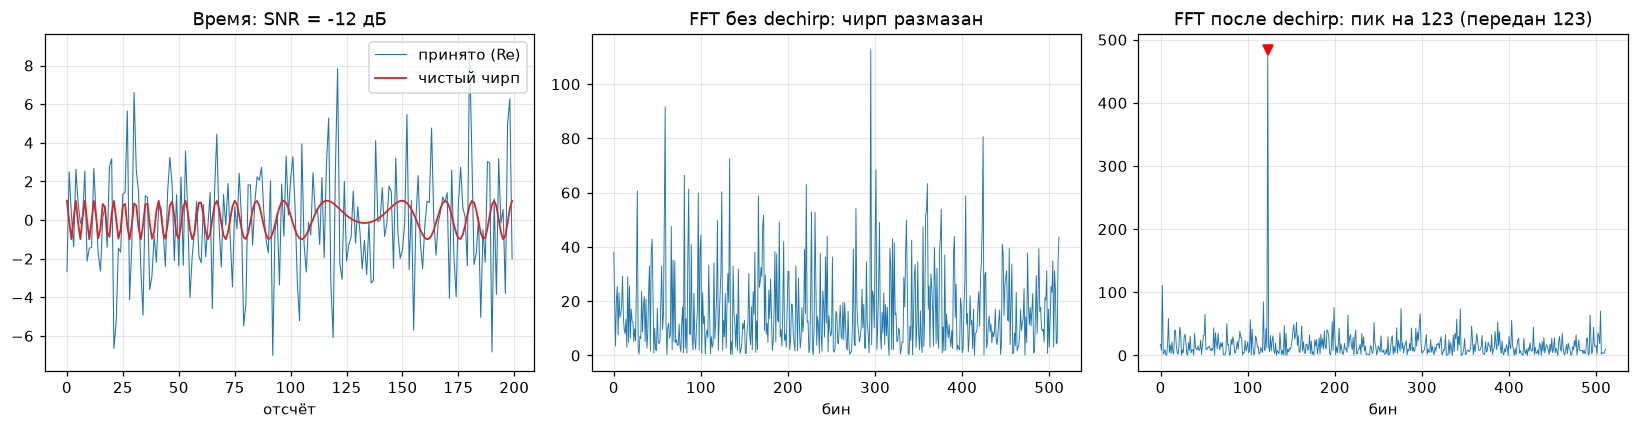

Пик над средним шумовым полом: 14.9 дБ (теория 10·log10(N·SNR) = 15.1 дБ)


In [4]:
s0 = 123 % N
r = chirp(s0, SF) + awgn(N, SNR_DB, rng)
sh, Y = demod(r, SF, return_spec=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(r.real[:200], lw=0.7, label="принято (Re)"); ax[0].plot(chirp(s0, SF).real[:200], "C3", lw=1.2, label="чистый чирп")
ax[0].set_xlabel("отсчёт"); ax[0].legend(); ax[0].set_title(f"Время: SNR = {SNR_DB} дБ")
ax[1].plot(np.abs(np.fft.fft(r))**2 / N, lw=0.6)
ax[1].set_xlabel("бин"); ax[1].set_title("FFT без dechirp: чирп размазан")
P = np.abs(Y)**2 / N
ax[2].plot(P, lw=0.6); ax[2].plot(sh, P[sh], "rv")
ax[2].set_xlabel("бин"); ax[2].set_title(f"FFT после dechirp: пик на {sh} (передан {s0})")
plt.tight_layout(); plt.show()
noise_floor = np.median(P) / np.log(2)                       # медиана Exp(μ) = μ·ln2
print(f"Пик над средним шумовым полом: {10*np.log10(P[sh]/noise_floor):.1f} дБ "
      f"(теория 10·log10(N·SNR) = {10*np.log10(N)+SNR_DB:.1f} дБ)")

## 3. SER против SNR для SF7…SF12
Ошибка — когда один из $N-1$ шумовых бинов перевысит сигнальный:
$$P_s=1-\int_0^\infty p_\text{Rice}(x)\,\big(1-e^{-x}\big)^{N-1}dx$$
Каждый шаг SF удваивает $N$: энергия символа растёт на 3 дБ, но и шумовых бинов-конкурентов вдвое больше, так что порог сдвигается на ~2.5 дБ. Точки — симуляция, линии — формула.

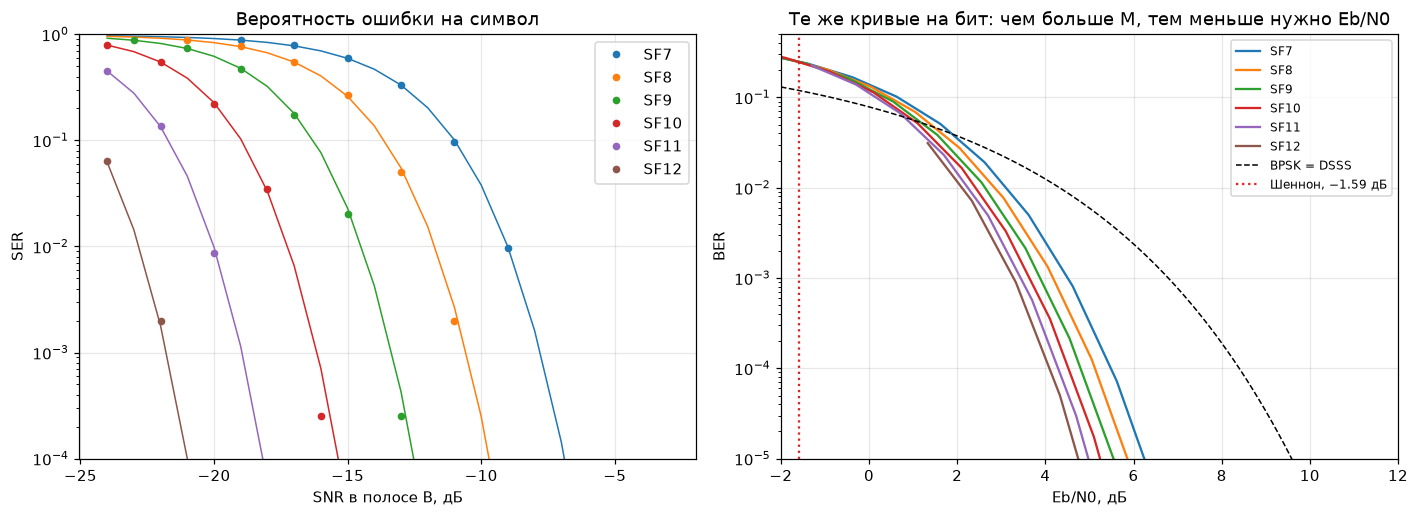

In [5]:
sfs = range(7, 13)
snr_grid = np.arange(-24, -2.9, 1.0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
thr = {}
for i, sf in enumerate(sfs):
    th = ser_theory(sf, snr_grid)
    ax[0].semilogy(snr_grid, th, f"C{i}-", lw=1)
    pts = snr_grid[(th > 3e-4) & (th < 0.9)][::2]
    ax[0].semilogy(pts, [sim_ser(sf, s, 4000, rng) for s in pts], f"C{i}o", ms=4, label=f"SF{sf}")
    thr[sf] = np.interp(-3, np.log10(th[::-1] + 1e-300), snr_grid[::-1])
    ebn0 = snr_grid + 10 * np.log10(2**sf / sf)              # Eb/N0 = SNR·N/SF
    ber = th * (2**sf / 2) / (2**sf - 1)
    ax[1].semilogy(ebn0, ber, f"C{i}-", label=f"SF{sf}")
from scipy.special import erfc
eb = np.linspace(-2, 12, 200)
ax[1].semilogy(eb, 0.5 * erfc(np.sqrt(10 ** (eb / 10))), "k--", lw=1, label="BPSK = DSSS")
ax[1].axvline(-1.59, color="C3", ls=":", label="Шеннон, −1.59 дБ")
ax[0].set_ylim(1e-4, 1); ax[0].set_xlabel("SNR в полосе B, дБ"); ax[0].set_ylabel("SER"); ax[0].legend(); ax[0].set_title("Вероятность ошибки на символ")
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlim(-2, 12); ax[1].set_xlabel("Eb/N0, дБ"); ax[1].set_ylabel("BER")
ax[1].legend(fontsize=8); ax[1].set_title("Те же кривые на бит: чем больше M, тем меньше нужно Eb/N0")
plt.tight_layout(); plt.show()

### Бюджет линии
Чувствительность $P_\text{min}=-174\ \text{дБм/Гц}+10\log_{10}B+NF+\text{SNR}_\text{min}$ ($NF=6$ дБ). В таблице — SNR для SER $10^{-3}$ по формуле выше (даташит Semtech даёт −7.5…−20 дБ: там другой критерий и реальный приёмник), скорость с кодом 4/5 и время в эфире пакета 20 байт. В свободном пространстве +6 дБ запаса = ×2 дальности; в городе (затухание $\propto d^{3.5}$) — ×1.5.

In [6]:
print(f" SF | SNR_min | Eb/N0 | чувств.  | R_b, бит/с | 20 Б в эфире | дальность ×(n=2) ×(n=3.5)")
for sf in sfs:
    sens = -174 + 10 * np.log10(BW) + 6 + thr[sf]
    d = thr[7] - thr[sf]
    print(f" {sf:2} | {thr[sf]:6.1f}  | {thr[sf] + 10*np.log10(2**sf/sf):5.1f} | {sens:6.1f} дБм | {bitrate(sf):9.0f}  | "
          f"{time_on_air(20, sf)*1e3:8.0f} мс  |    {10**(d/20):4.1f}    {10**(d/35):4.1f}")
print("\nКаждая ступень SF: ~+2.5 дБ к бюджету и ~×2 времени в эфире (батарея, duty cycle 1 % в Европе).")

 SF | SNR_min | Eb/N0 | чувств.  | R_b, бит/с | 20 Б в эфире | дальность ×(n=2) ×(n=3.5)
  7 |   -7.8  |   4.8 | -124.8 дБм |      5469  |       57 мс  |     1.0     1.0
  8 |  -10.6  |   4.5 | -127.6 дБм |      3125  |      103 мс  |     1.4     1.2
  9 |  -13.4  |   4.2 | -130.4 дБм |      1758  |      185 мс  |     1.9     1.4
 10 |  -16.2  |   3.9 | -133.2 дБм |       977  |      371 мс  |     2.6     1.7
 11 |  -19.0  |   3.7 | -136.0 дБм |       537  |      741 мс  |     3.6     2.1
 12 |  -21.8  |   3.5 | -138.8 дБм |       293  |     1319 мс  |     5.0     2.5

Каждая ступень SF: ~+2.5 дБ к бюджету и ~×2 времени в эфире (батарея, duty cycle 1 % в Европе).


## 4. Сдвиг частоты и времени: одна и та же ось
У чирпа частота и время связаны: сдвиг на $\Delta t$ отсчётов — это сдвиг по частоте на $\Delta t\cdot B/N$. Поэтому после dechirp и уход несущей $\Delta f$ (в бинах $\delta=\Delta f\,N/B$), и сдвиг окна $\tau$ дают одно и то же — **сдвиг пика**:
$$\text{up-чирп: } k_\uparrow=\tau+\delta,\qquad \text{down-чирп: } k_\downarrow=-\tau+\delta$$
Поэтому в преамбуле есть down-чирпы: два уравнения → $\delta=(k_\uparrow+k_\downarrow)/2$, $\tau=(k_\uparrow-k_\downarrow)/2$. Дробную часть $\delta$ даёт поворот фазы пика между соседними up-чирпами преамбулы: тон на $\delta$ бинах за $N$ отсчётов набирает $2\pi\delta$.

Кварцы ±`PPM` ppm на `FC_MHZ` МГц — это килогерцы, сотни бинов при SF12. Без оценки по преамбуле приёмник промахивается на весь сдвиг.

Истина: δ = 29.509 бина (7204 Гц), τ = 37. Оценка: δ̂ = 29.486, τ̂ = 37
SER данных при SNR -12 дБ: без коррекции 1.00, только целая часть δ 0.543, полная коррекция 0.000


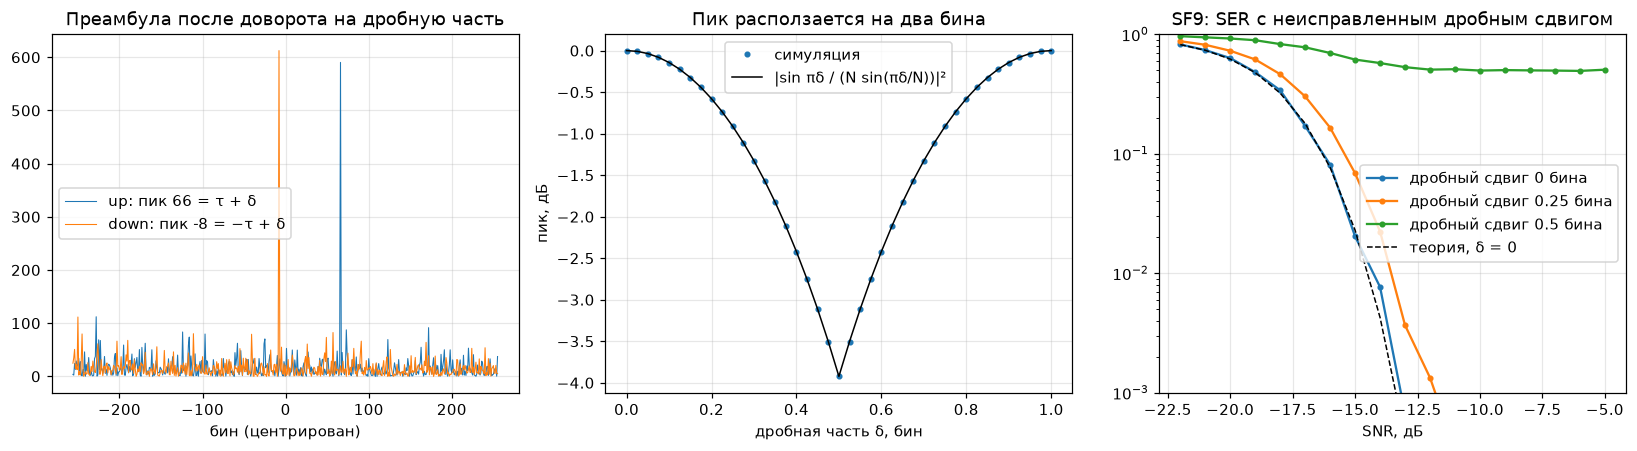

In [7]:
cfo_hz = PPM * 1e-6 * FC_MHZ * 1e6 * 0.83                     # какой-то сдвиг в пределах ±PPM
delta = cfo_hz / (BW / N)
def rx(x, delta, tau, snr_db, rng):
    """Сдвиг частоты на delta бинов, окно приёмника позже на tau отсчётов, шум."""
    n = np.arange(len(x))
    y = x * np.exp(2j * np.pi * delta * n / N) * np.exp(1j * rng.uniform(0, 2 * np.pi))
    y = np.r_[y, np.zeros(N)][tau:tau + len(x)]
    return y + awgn(len(y), snr_db, rng)

pre = np.r_[chirp(np.zeros(8, int), SF).ravel(), chirp(np.zeros(2, int), SF, down=True).ravel()]
data = rng.integers(0, N, 200)
tx = np.r_[pre, chirp(data, SF).ravel()]
y = rx(tx, delta, TIMING, SNR_DB, rng)

wrap = lambda k: (k + N // 2) % N - N // 2
def preamble_peaks(y):
    """Окна 1…6 up-чирпов и первое окно down-чирпов целиком лежат внутри своих участков при 0 ≤ τ < N."""
    Yu = np.fft.fft(y[N:7 * N].reshape(6, N) * chirp(0, SF, down=True), axis=1)
    Yd = np.fft.fft(y[8 * N:9 * N] * chirp(0, SF))
    return Yu, Yd
# шаг 1: дробная часть δ — по набегу фазы пика между соседними up-чирпами (от τ не зависит)
Yu, Yd = preamble_peaks(y)
pk = np.abs(Yu).sum(0).argmax()
d_frac = np.angle(np.sum(Yu[1:, pk] * np.conj(Yu[:-1, pk]))) / (2 * np.pi)
# шаг 2: убрали дробную часть → пики встают точно на целые бины τ+δ_int и −τ+δ_int
y_c = y * np.exp(-2j * np.pi * d_frac * np.arange(len(y)) / N)
Yu, Yd = preamble_peaks(y_c)
ku = wrap(np.abs(Yu).sum(0).argmax()); kd = wrap(np.abs(Yd).argmax())
d_int = (ku + kd) / 2; tau_hat = (ku - kd) / 2
d_hat = d_int + d_frac

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
kk = np.arange(N) - N // 2
ax[0].plot(kk, np.fft.fftshift(np.abs(Yu[2])**2) / N, lw=0.7, label=f"up: пик {ku} = τ + δ")
ax[0].plot(kk, np.fft.fftshift(np.abs(Yd)**2) / N, lw=0.7, label=f"down: пик {kd} = −τ + δ")
ax[0].set_xlabel("бин (центрирован)"); ax[0].legend(); ax[0].set_title(f"Преамбула после доворота на дробную часть")

def demod_data(y, d_hat, tau_hat, n):
    n0 = 10 * N - int(round(tau_hat))
    seg = y[n0:n0 + n * N]
    seg = seg * np.exp(-2j * np.pi * d_hat * np.arange(len(seg)) / N)
    seg = np.r_[seg, np.zeros(n * N - len(seg))]
    return demod(seg.reshape(n, N), SF)
ser_none = np.mean(demod(y[10 * N:10 * N + 199 * N].reshape(199, N), SF) != data[:199])
ser_int = np.mean(demod_data(y, np.round(d_int), tau_hat, 199) != data[:199])
ser_full = np.mean(demod_data(y, d_hat, tau_hat, 199) != data[:199])
print(f"Истина: δ = {delta:.3f} бина ({cfo_hz:.0f} Гц), τ = {TIMING}. Оценка: δ̂ = {d_hat:.3f}, τ̂ = {tau_hat:.0f}")
print(f"SER данных при SNR {SNR_DB} дБ: без коррекции {ser_none:.2f}, только целая часть δ {ser_int:.3f}, полная коррекция {ser_full:.3f}")

# потери от дробного сдвига
fr = np.linspace(0, 1, 41)
meas = [np.abs(np.fft.fft(chirp(0, SF) * np.exp(2j * np.pi * f * np.arange(N) / N) * chirp(0, SF, down=True))).max()**2 / N**2 for f in fr]
th = np.abs(np.sin(np.pi * np.minimum(fr, 1 - fr)) / (N * np.sin(np.pi * np.minimum(fr, 1 - fr) / N) + 1e-30))**2
th[np.minimum(fr, 1 - fr) == 0] = 1
ax[1].plot(fr, 10 * np.log10(meas), "C0o", ms=3, label="симуляция")
ax[1].plot(fr, 10 * np.log10(th), "k", lw=1, label="|sin πδ / (N sin(πδ/N))|²")
ax[1].set_xlabel("дробная часть δ, бин"); ax[1].set_ylabel("пик, дБ"); ax[1].legend(); ax[1].set_title("Пик расползается на два бина")

snr_g = np.arange(-22, -4, 1.0) + (SF - 9) * -2.5
for i, f in enumerate([0, 0.25, 0.5]):
    ax[2].semilogy(snr_g, [sim_ser(SF, s, 3000, rng, cfo_bins=f) for s in snr_g], f"C{i}o-", ms=3, label=f"дробный сдвиг {f} бина")
ax[2].semilogy(snr_g, ser_theory(SF, snr_g), "k--", lw=1, label="теория, δ = 0")
ax[2].set_ylim(1e-3, 1); ax[2].set_xlabel("SNR, дБ"); ax[2].legend(); ax[2].set_title(f"SF{SF}: SER с неисправленным дробным сдвигом")
plt.tight_layout(); plt.show()

## 5. Помехи: тон и другие SF
**Узкополосная помеха.** Тон после умножения на down-чирп сам становится чирпом и размазывается по всем $N$ бинам — ровно как глушилка в DSSS. Слева: тон на `JSR_DB` дБ сильнее сигнала, пик всё равно на месте.

**Квазиортогональность SF.** Чирп SF$_b$, продемодулированный down-чирпом SF$_a\ne$SF$_b$, — снова чирп (скорости $B^2/2^{SF}$ разные, остаётся разностная), и его энергия тоже растекается по бинам. Поэтому разные SF на одной частоте почти не мешают друг другу — это даёт LoRaWAN-шлюзу 6 «логических каналов» на одной частоте. «Почти»: справа матрица порогов — при каком отношении сигнал/помеха (SIR) SER полезного сигнала падает до 1 % (без шума, помеха со случайным сдвигом по времени и фазе). На диагонали — тот же SF: **захват**, побеждает сильнейший. Без шума порог ≈0 дБ (энергия несинхронной помехи делится между двумя бинами); в реальном приёмнике с шумом и замираниями закладывают +1…+6 дБ.

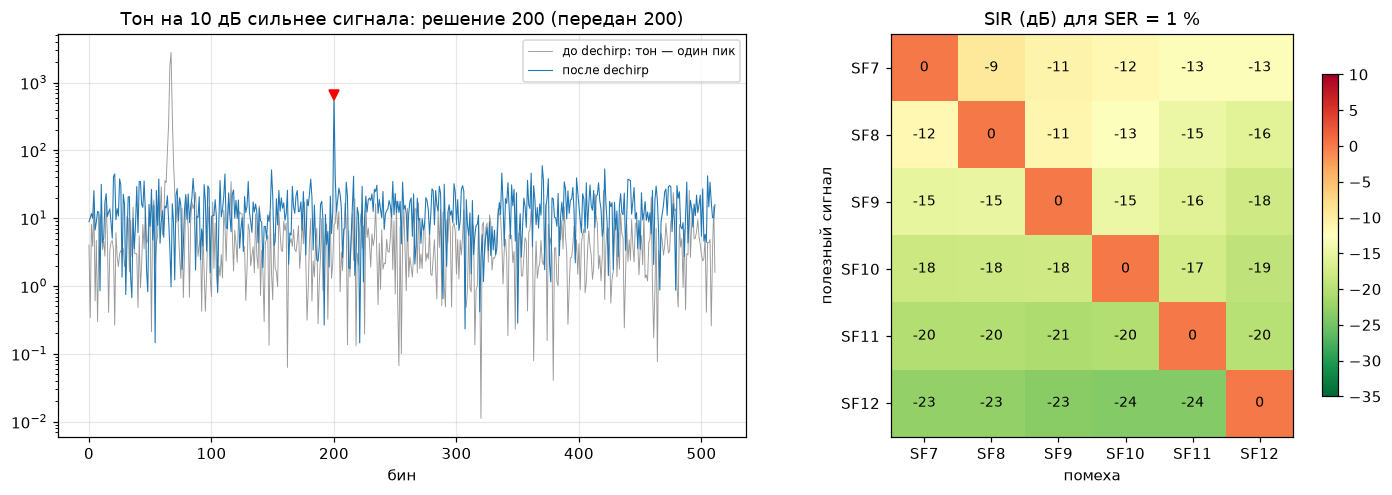

Ниже нуля — полезный сигнал слабее помехи и всё равно принимается.
Диагональ (тот же SF, захват): [0.1 0.  0.  0.  0.  0. ] дБ


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
s0 = 200 % N
n = np.arange(N)
tone = 10 ** (JSR_DB / 20) * np.exp(2j * np.pi * (0.13 * n + rng.random()))
r = chirp(s0, SF) + tone + awgn(N, SNR_DB + 6, rng)
sh, Y = demod(r, SF, return_spec=True)
ax[0].plot(np.abs(np.fft.fft(r))**2 / N, "0.6", lw=0.6, label="до dechirp: тон — один пик")
ax[0].plot(np.abs(Y)**2 / N, "C0", lw=0.7, label="после dechirp")
ax[0].plot(sh, np.abs(Y[sh])**2 / N, "rv")
ax[0].set_yscale("log"); ax[0].set_xlabel("бин"); ax[0].legend(fontsize=8)
ax[0].set_title(f"Тон на {JSR_DB} дБ сильнее сигнала: решение {sh} (передан {s0})")

def interferer(sf_i, n_samp, rng):
    """Непрерывный поток символов SF_i со случайным сдвигом по времени и фазе."""
    Ni = 2**sf_i
    k = n_samp // Ni + 2
    x = chirp(rng.integers(0, Ni, k), sf_i).ravel()
    off = rng.integers(0, Ni)
    return x[off:off + n_samp] * np.exp(1j * rng.uniform(0, 2 * np.pi))

def ser_sir(sf_a, sf_b, sir_db, n_sym, rng):
    Na = 2**sf_a
    s = rng.integers(0, Na, n_sym)
    I = np.stack([interferer(sf_b, Na, rng) for _ in range(n_sym)])
    r = chirp(s, sf_a) + 10 ** (-sir_db / 20) * I
    return np.mean(demod(r, sf_a) != s)

sir_grid = np.arange(-40, 12, 1.0)
Mthr = np.full((6, 6), np.nan)
for a, sfa in enumerate(sfs):
    for b, sfb in enumerate(sfs):
        lo, hi = -45.0, 15.0                                  # бисекция: SER(SIR) монотонна
        for _ in range(9):
            mid = (lo + hi) / 2
            if ser_sir(sfa, sfb, mid, 300 if sfa < 11 else 150, rng) > 0.01: lo = mid
            else: hi = mid
        Mthr[a, b] = hi
im = ax[1].imshow(Mthr, cmap="RdYlGn_r", vmin=-35, vmax=10)
for a in range(6):
    for b in range(6):
        ax[1].text(b, a, f"{Mthr[a, b]:.0f}", ha="center", va="center", fontsize=9)
ax[1].set_xticks(range(6), [f"SF{s}" for s in sfs]); ax[1].set_yticks(range(6), [f"SF{s}" for s in sfs])
ax[1].set_xlabel("помеха"); ax[1].set_ylabel("полезный сигнал"); ax[1].grid(False)
ax[1].set_title("SIR (дБ) для SER = 1 %"); plt.colorbar(im, ax=ax[1], shrink=0.8)
plt.tight_layout(); plt.show()
print("Ниже нуля — полезный сигнал слабее помехи и всё равно принимается.")
print(f"Диагональ (тот же SF, захват): {np.round(np.diag(Mthr), 1)} дБ")

## Сравнение с CDMA и LTE
| | DSSS / CDMA | CSS / LoRa | OFDM / LTE |
|---|---|---|---|
| Чем расширяется спектр | ПСП, $N$ чипов на **1 бит** | чирп, $N$ отсчётов на **SF бит** | не расширяется: $N$ параллельных потоков |
| Выигрыш против белого шума | 0 дБ (BPSK) | растёт с SF (ортогональная $M$-ичная) | 0, выигрыш даёт код |
| Узкополосная помеха | давится в $N$ раз | давится в $N$ раз | бьёт свои поднесущие, спасает код |
| Синхронизация | поиск фазы кода (корреляция) | одна FFT: время и частота — один сдвиг пика | CP + пилоты, чувствителен к сдвигу частоты |
| Пик-фактор | низкий | **0 дБ** — дешёвый нелинейный усилитель | высокий |
| Спектральная эффективность | низкая | очень низкая: $SF/2^{SF}$ бит/с/Гц | высокая |

Почему чирп, а не обычная $M$-FSK с теми же $N$ тонами? У FSK каждый символ — **узкая** линия, и её съедает провал АЧХ или узкополосная помеха. Чирп каждого символа проходит всю полосу $B$ — дает частотное разнесение внутри символа и подавление помех, сохраняя постоянную огибающую. Цена — та же, что у DSSS: полоса и скорость.

## Что покрутить
- `SNR_DB = -20` при `SF = 12` — разделы 2 и 4 всё ещё работают; при `SF = 7` — уже нет: порог SF7 около −7…−8 дБ
- `PPM = 40` (дешёвые кварцы) — сдвиг уходит за $N/2$ бинов при малых SF и оценка по преамбуле «заворачивается»; поэтому для SF11–12 есть ограничение на дрейф и режим LDRO
- `TIMING` больше `N // 2` — оценка τ по преамбуле неоднозначна по модулю $N$: на практике первый грубый поиск идёт скольжением окна по преамбуле
- `BW = 500e3` — та же картина в 4 раза быстрее, но чувствительность хуже на 6 дБ (шум в полосе)
- `JSR_DB = 30` при `SF = 7` — тон пробивает: подавление ограничено $10\log_{10}N=21$ дБ
- в `ser_sir` убрать случайный сдвиг по времени (`off = 0`) — помеха того же SF, выровненная по символам, ведёт себя иначе: это уже два тона в одном FFT